# From Trend to Waste: every algorithm, run step by step

*Business Data Analytics project · Madhusudhanan G · Pharos Sophy Samuel T J · Sri Charan*

This notebook reruns the project's analysis in Google Colab. Each step has three parts:
1. **What it does**, in plain words.
2. **The algorithm**: the actual code from our project (`src/`).
3. **Run it and see the results**: the same numbers and charts as in our slides.

**How to run it (about 10-15 minutes):**
1. Put `From_Trend_to_Waste_colab_pack.zip` in your Google Drive (anywhere in *My Drive*), or upload it when the first cell asks.
2. Click **Runtime → Run all**, and allow Drive access when asked.

All retail data comes from **one retailer, Nuna Lie** (an Italian fast-fashion chain), through the **VISUELLE 2.0** dataset: sales, deliveries, prices, discounts and loyalty-card purchases, linked by product code, shop and date. The consumer side is our own survey.

*The pack contains licensed data (VISUELLE 2.0) and our survey export. Use it for this course only and do not share it publicly.*

| Step | Question | Algorithms |
|---|---|---|
| 1 | How much stock is left over? Can we forecast the season after 2 weeks? What if we act early? | Stock replay, naive forecast, Poisson regression, gradient boosting, WAPE, fixed-effects regression, simulation, break-even |
| 2 | How do products sell over their life? When are they marked down? | K-means clustering, silhouette score, short-lived rule, markdown detection |
| 3 | Can we predict high leftover before launch, and after 2 weeks? | Logistic regression, decision tree, gradient boosting, ROC-AUC, odds ratios |
| 4 | Who buys? | RFM features, K-means segmentation, CLTV, Spearman correlation |
| 5 | What do market trends show? | Moving average, linear trendline, seasonal index, Google Trends test |
| 6 | How would we prove it works in real shops? | Power analysis (t-test) |
| 7 | What does excess stock cost? | Financial statements built from the data (markdown rate, stock-to-sales, turnover, margins) |
| 8 | What do consumers say? | Conjoint analysis (OLS with fixed effects), bootstrap, K-means, Spearman |

## 0 · Setup

In [1]:
import os, sys, glob, zipfile, subprocess

IN_COLAB = "google.colab" in sys.modules
PACK_NAME = "From_Trend_to_Waste_colab_pack.zip"
WORK = "/content/BDA-Project" if IN_COLAB else os.path.abspath("bda_colab_run")

if IN_COLAB:
    from google.colab import drive
    hits = []
    try:
        drive.mount("/content/drive")
        hits = (glob.glob(f"/content/drive/MyDrive/{PACK_NAME}") + glob.glob(f"/content/drive/MyDrive/*/{PACK_NAME}")
                or glob.glob(f"/content/drive/MyDrive/**/{PACK_NAME}", recursive=True))
    except Exception as e:
        print("Drive not mounted:", e)
    if not hits:
        from google.colab import files
        print(f"{PACK_NAME} not found in Drive: please choose it to upload")
        hits = [os.path.abspath(name) for name in files.upload()]
    pack = hits[0]
else:  # running on a laptop: the pack sits next to the project in deliverables/colab/
    pack = os.environ.get("BDA_PACK", os.path.join("..", "deliverables", "colab", PACK_NAME))

os.makedirs(WORK, exist_ok=True)
zipfile.ZipFile(pack).extractall(WORK)
os.chdir(WORK)
sys.path.insert(0, WORK)
print("Unpacked", os.path.basename(pack), "into", WORK)

Unpacked From_Trend_to_Waste_colab_pack.zip into /private/tmp/claude-501/-Users-pharos-Documents-GitHub-BDA-Project/c1b6f177-f946-4a19-967b-769da725b124/scratchpad/nbrun3/bda_colab_run


In [2]:
# Same library versions as the project (falls back to Colab's own versions if a pin is unavailable)
def pip(*args):
    return subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args]).returncode

if IN_COLAB and pip("scikit-learn==1.9.1", "statsmodels==0.15.0", "polars==1.44.2", "duckdb==1.5.5") != 0:
    pip("-U", "scikit-learn", "statsmodels", "polars", "duckdb")

In [3]:
import inspect, json, warnings
import pandas as pd
from IPython.display import Code, Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def show(fn, start=None, stop=None):
    """Print the project's own code for a function (optionally only the lines from `start` to `stop`)."""
    lines = inspect.getsource(fn).splitlines()
    i = next((k for k, l in enumerate(lines) if start in l), 0) if start else 0
    j = next((k for k, l in enumerate(lines) if k >= i and stop in l), len(lines) - 1) if stop else len(lines) - 1
    display(Code("\n".join(lines[i:j + 1]), language="python"))


def fig(name, width=900):
    display(Image(filename=f"outputs/figures/{name}.png", width=width))


def table(name):
    return pd.read_csv(f"outputs/tables/{name}.csv")


def js(name):
    return json.load(open(f"outputs/tables/{name}.json"))


def say(text):
    display(Markdown(text))


pct = lambda x, d=1: f"{x * 100:.{d}f}%"

## 1 · Leftover stock, week-2 forecasting and the what-if simulation

**What it does.** VISUELLE 2.0 has real deliveries and weekly sales for 5,355 products in 110 shops (106,850 product-shops).
- **Leftover stock**: deliveries minus sales after each product's first 12 weeks, replayed shop by shop, week by week.
- **Forecasting weeks 3-12 from weeks 1-2**: a **naive** forecast (last week repeats), a **category lifecycle profile**, **Poisson regression** and **gradient boosting**, with and without **Google Trends**. Trained on the 2017-18 seasons, tested on 2019. Error is measured with **WAPE** (total absolute error ÷ total sales).
- **Markdown uplift**: a **fixed-effects regression** estimates how much a discount raises sales.
- **Simulation**: replay the 2019 seasons. Products the forecast flags at week 2 (predicted sell-through below 60%) get fewer later deliveries and/or a 20% markdown from week 4. We compare unsold stock, units sold and revenue.

**The algorithm (our code):**

In [4]:
from src import vis_forecast as V
show(V.stock_path)          # stock at the end of each week = deliveries so far - sales so far
show(V.fit_forecasters)     # naive, lifecycle profile, Poisson regression, gradient boosting (+/- Google Trends)
show(V.forecast_metrics)    # WAPE
show(V.estimate_uplift)     # fixed-effects regression for the markdown uplift
show(V.simulate)            # week-by-week stock replay under a policy

def stock_path(D, S):
    """Start-of-week available stock and end-of-week stock for each product-shop."""
    cumD = D.cumsum(1)
    sold_before = np.concatenate([np.zeros((len(S), 1)), S.cumsum(1)[:, :-1]], 1)
    avail = cumD - sold_before
    return avail, avail - S

def fit_forecasters(X):
    tr, te = X[X.season.isin(TRAIN)].copy(), X[X.season.isin(TEST)].copy()
    preds = {}
    # 1. Naive: week-2 sales carried forward
    preds["Naive (last week repeats)"] = te.w2.values.astype(float)
    # 2. Category lifecycle profile: ratio of sums, week h vs weeks 1-2, estimated on training seasons
    base = tr.w1 + tr.w2
    prof = (tr.assign(base=base).groupby(["category", "h"], observed=True)
              .apply(lambda g: g.y.sum() / max(g.base.sum(), 1), include_groups=False))
    glob = tr.assign(base=base).groupby("h").apply(lambda g: g.y.sum() / g.base.sum(), include_groups=False)
    ratio = [prof.get((c, h), glob[h]) for c, h in zip(te.category, te.h)]
    preds["Category lifecycle profile"] = (te.w1 + te.w2).values * np.array(ratio)
    # 3. Poisson regression (a linear model on the log scale, suited to counts), one-hot categories
    Xl_tr = pd.get_dummies(tr[NUMF + CATF], columns=CATF + ["h"], dtype=float)
    Xl_te = pd.get_dummies(te[NUMF + CATF], columns=CATF + ["h"], dtype=float).reindex(columns=Xl_tr.columns, fill_value=0)
    med = Xl_tr.median()
    sc = StandardScaler().fit(Xl_tr.fillna(med))
    pois = PoissonRegressor(alpha=1e-3, max_iter=2000).fit(sc.transform(Xl_tr.fillna(med)), tr.y)
    preds["Poisson regression"] = pois.predict(sc.transform(Xl_te.fillna(med)))
    # 4. Gradient boosting with Poisson loss (native categorical support)
    gbm = HistGradientBoostingRegressor(loss="poisson", max_iter=600, learning_rate=0.05, max_leaf_nodes=31,
                                        categorical_features="from_dtype",
                                        random_state=RANDOM_STATE)
    gbm.fit(tr[NUMF + CATF], tr.y)
    preds["Gradient boosting + Google Trends"] = gbm.predict(te[NUMF + CATF])
    # 5. Ablation: identical model without the Google Trends (market-interest) features
    no_gt = [f for f in NUMF if not f.startswith("gt_")]
    gbm_ngt = HistGradientBoostingRegressor(loss="poisson", max_iter=600, learning_rate=0.05, max_leaf_nodes=31,
                                            categorical_features="from_dtype", random_state=RANDOM_STATE)
    gbm_ngt.fit(tr[no_gt + CATF], tr.y)
    preds["Gradient boosting (no Google Trends)"] = gbm_ngt.predict(te[no_gt + CATF])
    return tr, te, preds, gbm

def forecast_metrics(te, preds):
    rows = []
    y = te.y.values
    for name, f in preds.items():
        e = f - y
        tot = te.assign(f=f).groupby("external_code").agg(f=("f", "sum"), y=("y", "sum"))
        for grp, m in (("All products", np.ones(len(te), bool)), ("Short-lived", te.short_lived.values),
                       ("Other", ~te.short_lived.values)):
            rows.append({"model": name, "group": grp,
                         "weekly_wape": np.abs(e[m]).sum() / y[m].sum(),
                         "weekly_mae": np.abs(e[m]).mean(),
                         "bias": e[m].sum() / y[m].sum()})
        rows[-3]["remaining_total_wape"] = (tot.f - tot.y).abs().sum() / tot.y.sum()
    return pd.DataFrame(rows)

def estimate_uplift(S, Dsc):
    """Markdown uplift: log(1+sales) on discount with product-shop and week fixed effects
    (two-way demeaning of the balanced 12-week panel), plus a first-difference check."""
    y, x = np.log1p(S), Dsc
    dm = lambda a: a - a.mean(1, keepdims=True) - a.mean(0, keepdims=True) + a.mean()
    yd, xd = dm(y), dm(x)
    beta = (xd * yd).sum() / (xd * xd).sum()
    g = (xd * (yd - beta * xd)).sum(1)
    se = np.sqrt((g ** 2).sum()) / (xd * xd).sum()
    dy, dx = np.diff(y, axis=1), np.diff(x, axis=1)
    m = dx != 0
    b_fd = (dx[m] * dy[m]).sum() / (dx[m] ** 2).sum()
    return {"beta_fe": float(beta), "se_fe_cluster": float(se), "beta_fd": float(b_fd),
            "uplift_per_10pp_fe": float(np.exp(beta * 0.1) - 1), "uplift_per_10pp_fd": float(np.exp(b_fd * 0.1) - 1)}

def simulate(D, S, Dsc, price, flag_rows, r_cut=0.0, md_level=None, md_week=3, beta=0.882):
    """Replay one season at product-shop level under a policy.
    Demand = observed sales (lower bound; stock-outs are rare) scaled by the markdown uplift.
    Policy A: for flagged product-shops, deliveries after the 2 observed weeks are cut by r_cut.
    Policy B: for flagged product-shops, discount raised to at least md_level from week md_week+1.
    """
    D2 = D.copy()
    if r_cut:
        D2[flag_rows, ORIGIN:] *= (1 - r_cut)
    dsc2 = Dsc.copy()
    if md_level is not None:
        sub = dsc2[flag_rows, md_week:]
        dsc2[flag_rows, md_week:] = np.maximum(sub, md_level)
    demand = S * np.exp(beta * (dsc2 - Dsc))
    stock = np.zeros(len(S))
    sold = np.zeros_like(S)
    for k in range(K):
        stock += D2[:, k]
        sold[:, k] = np.minimum(demand[:, k], np.maximum(stock, 0))
        stock -= sold[:, k]
    revenue = (price[:, None] * (1 - dsc2) * sold).sum()
    return {"delivered": D2.sum(), "sold": sold.sum(), "leftover": np.maximum(stock, 0).sum(), "revenue": revenue,
            "purchase_value_full_price": (price[:, None] * D2).sum()}

In [5]:
V.main()   # run step 1 (the longest step, a few minutes)

                                   model         group  weekly_wape  weekly_mae  bias  remaining_total_wape
0              Naive (last week repeats)  All products        0.602      15.775 0.310                 0.501
1              Naive (last week repeats)   Short-lived        1.397      16.376 1.226                   NaN
2              Naive (last week repeats)         Other        0.584      15.744 0.290                   NaN
3             Category lifecycle profile  All products        0.430      11.277 0.037                 0.325
4             Category lifecycle profile   Short-lived        0.833       9.762 0.530                   NaN
5             Category lifecycle profile         Other        0.421      11.354 0.027                   NaN
6                     Poisson regression  All products        0.524      13.747 0.337                 0.387
7                     Poisson regression   Short-lived        0.673       7.886 0.204                   NaN
8                     Poisso

stock : {'negative_sales_cells_clipped': 3386, 'units_delivered_after_week12_excluded': 62711, 'product_shops': 106850, 'products': 5355, 'shops': 110, 'seasons': ['AW17', 'AW18', 'AW19', 'SS17', 'SS18', 'SS19'], 'share_shop_weeks_ending_at_zero_stock': 0.01981828107939479, 'share_product_shops_ever_stocked_out_12w': 0.07421619092185307, 'units_delivered_12w': 2334430.0, 'units_sold_12w': 1602545.0, 'leftover_units_12w_product_shop': 736546.0, 'leftover_share_of_delivered': 0.3155142797171044, 'median_product_sell_through': 0.7186440677966102, 'share_products_sell_through_below_60pct': 0.15779645191409897, 'share_products_short_lived': 0.05322128851540616, 'short_lived_post_peak_shop_weeks_with_stock_available': 0.9385867196202838, 'short_lived_leftover_share': 0.22914755101149123, 'other_leftover_share': 0.31535713536678295, 'spearman_time_to_peak_vs_leftover_share': -0.02242521090808255, 'spearman_time_to_peak_p_value': 0.10111495571754522, 'share_products_marked_down_15pct_12w': 0.5

,model,weekly_wape,remaining_total_wape,bias
0,Naive (last week repeats),0.602,0.501,0.310
3,Category lifecycle profile,0.430,0.325,0.037
6,Poisson regression,0.524,0.387,0.337
9,Gradient boosting + Google Trends,0.394,0.264,0.184
12,Gradient boosting (no Google Trends),0.389,0.261,0.177


**Results**
- **31.6% of delivered units were still unsold after 12 weeks**; only 2.0% of shop-weeks ended at zero stock
- Best forecast: **Gradient boosting (no Google Trends)**, weekly WAPE **39%** vs naive 60%
- Week-2 rule (flag if predicted sell-through < 60%, cut later deliveries 30%, 20% markdown from week 4): unsold stock **-11.9%**, units sold 0.8%, revenue **-0.7%**

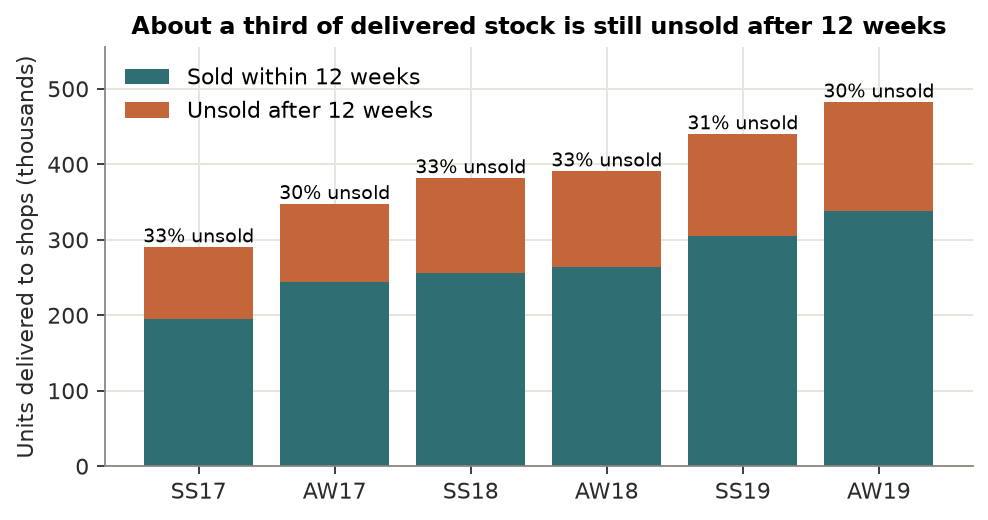

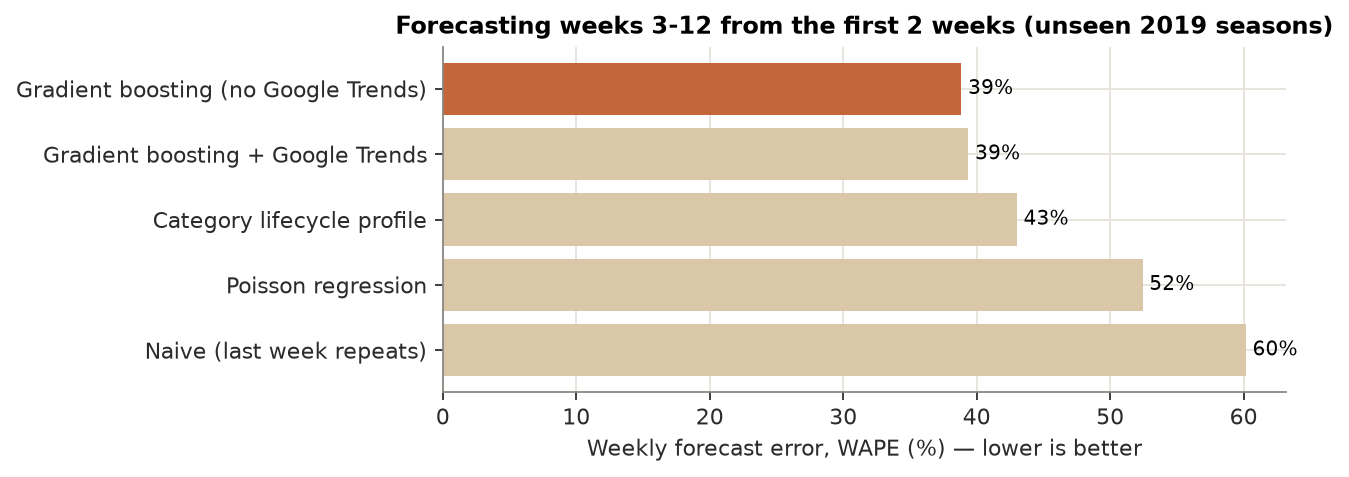

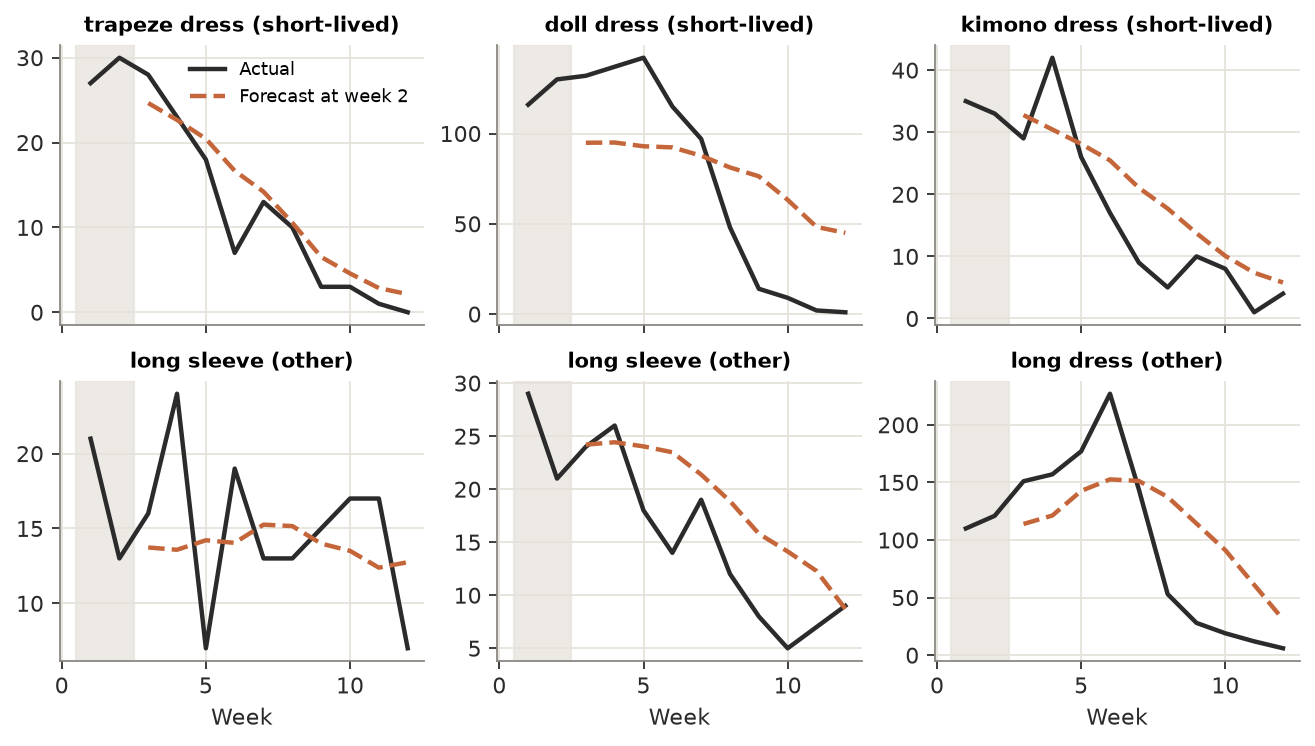

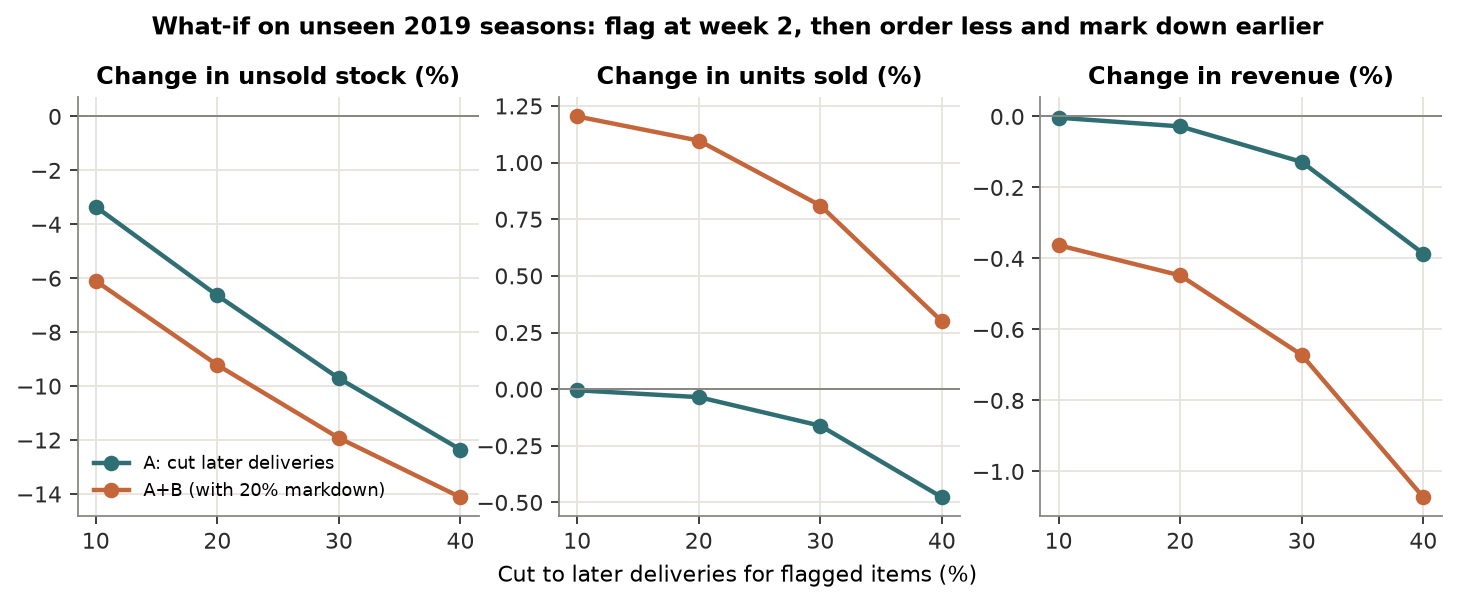

In [6]:
f = table("vis_forecast_metrics")
display(f[f.group == "All products"][["model", "weekly_wape", "remaining_total_wape", "bias"]])
v = js("vis_summary")
st, sim = v["stock"], v["simulation_main_scenario"]
say(f"""**Results**
- **{pct(st["leftover_share_of_delivered"])} of delivered units were still unsold after 12 weeks**; only {pct(st["share_shop_weeks_ending_at_zero_stock"])} of shop-weeks ended at zero stock
- Best forecast: **{v["forecast_best_model"]}**, weekly WAPE **{pct(v["forecast_best_weekly_wape"], 0)}** vs naive {pct(v["forecast_naive_weekly_wape"], 0)}
- Week-2 rule (flag if predicted sell-through < 60%, cut later deliveries 30%, 20% markdown from week 4): unsold stock **{pct(sim["leftover_change"])}**, units sold {pct(sim["sold_change"])}, revenue **{pct(sim["revenue_change"])}**""")
fig("vis_leftover_by_season", 600); fig("vis_forecast_models"); fig("vis_forecast_examples"); fig("vis_simulation")

## 2 · Demand lifecycles and markdown timing (end of season)

**What it does.** For every product with at least 30 units sold, we add up its first 12 weeks of sales across all shops and turn it into a curve showing the share of its sales in each week. Then:
- **K-means clustering** groups products with similar curves. The **silhouette score** helps choose how many groups to use.
- A **fixed rule** marks a product *short-lived* if its weekly sales fall below a quarter of the peak within 4 weeks of the peak, **and** weeks 7-12 carry less than 20% of its sales.
- **Markdown detection**: a product counts as marked down in any week its average discount across shops is at least 15%.

**The algorithm (our code):**

In [7]:
from src import vis_lifecycle as LC
show(V.short_lived_flag)                                          # the short-lived rule
show(LC.main, "for k in range(3, 8):", "names = name_clusters")   # K-means for k = 3..7 + silhouette score
show(LC.name_clusters)                                            # readable names from each cluster's shape

def short_lived_flag(U):
    """Short-lived product (rule fixed before modelling): weekly sales fall below 25% of the peak
    within 4 weeks of the peak, and the last 6 of the 12 weeks carry < 20% of 12-week units."""
    peak_w, peak = U.argmax(1), U.max(1)
    tot = U.sum(1)
    within = np.zeros(len(U), bool)
    for i in range(len(U)):
        after = U[i, peak_w[i] + 1: peak_w[i] + 5]
        within[i] = (after < 0.25 * peak[i]).any()
    last6 = U[:, 6:].sum(1) / np.where(tot > 0, tot, 1)
    return within & (last6 < 0.20) & (tot > 0)

for k in range(3, 8):
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(shares)
        scores[k], models[k] = float(silhouette_score(shares[samp], km.labels_[samp])), km
    k_best = max(scores, key=scores.get)
    for k in (4, 5):  # prefer an interpretable 4-5 clusters if within 0.02 of the best silhouette
        if scores[k] >= scores[k_best] - 0.02:
            k_best = k
            break
    km = models[k_best]
    names = name_clusters(km.cluster_centers_)

def name_clusters(centers):
    """Name clusters from their centre shapes (every centre is a share of 12-week sales by week)."""
    names = {}
    for c, v in enumerate(centers):
        first3, last6 = v[:3].sum(), v[6:].sum()
        later_peak = int(v[2:].argmax()) + 2
        if last6 >= 0.45:
            names[c] = "Late bloomer"
        elif first3 >= 0.42:
            names[c] = "Fast fade"
        elif 3 <= later_peak <= 8 and v[later_peak] > 1.05 * v[2]:
            names[c] = "Mid-season peak"
        else:
            names[c] = "Steady decline"
    seen = {}
    for c in sorted(names):
        if names[c] in seen:
            names[c] = f"{names[c]} {seen[names[c]] + 1}"
        seen[names[c]] = seen.get(names[c], 0) + 1
    return names

In [8]:
LC.main()   # run step 2

      cluster_name  products       units  median_peak_week  mean_share_last6  median_weeks_peak_to_half  share_marked_down  share_short_lived  median_sell_through  share_products
0   Steady decline      1181 266,976.000             1.000             0.351                      3.000              0.644              0.000                0.716           0.252
1        Fast fade      1219 260,301.000             2.000             0.205                      4.000              0.382              0.139                0.735           0.260
2  Mid-season peak      1267 524,376.000             3.000             0.350                      4.000              0.455              0.005                0.722           0.270
3     Late bloomer      1020 539,812.000             5.000             0.514                      2.000              0.806              0.000                0.700           0.218
   short_lived  products_marked_down  median_peak_week  median_first_markdown_week  median_weeks_peak_to_

**Results**
- Silhouette by number of clusters: k=3: 0.145, k=4: 0.135, k=5: 0.121, k=6: 0.105, k=7: 0.098 → we use **k = 4**
- Clusters: Steady decline 25%, Fast fade 26%, Mid-season peak 27%, Late bloomer 22%
- Short-lived products: **3.8%** (176 of 4,687); median sell-through 78% vs 72% for the others
- **44% of marked-down products were cut only after demand had halved**; demand at the first markdown was 53% of peak (median)

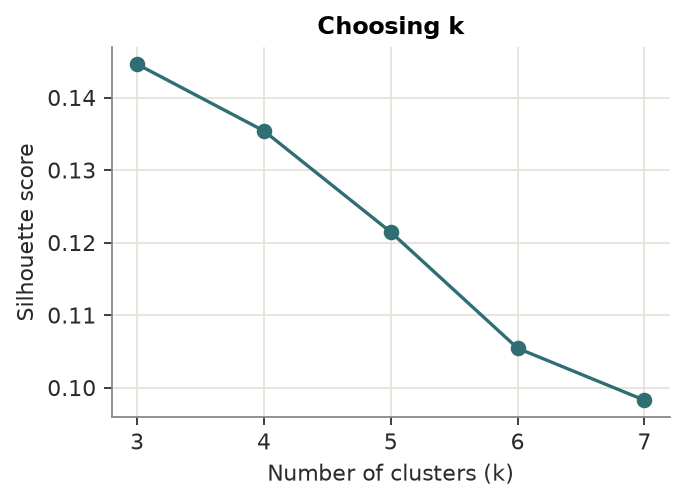

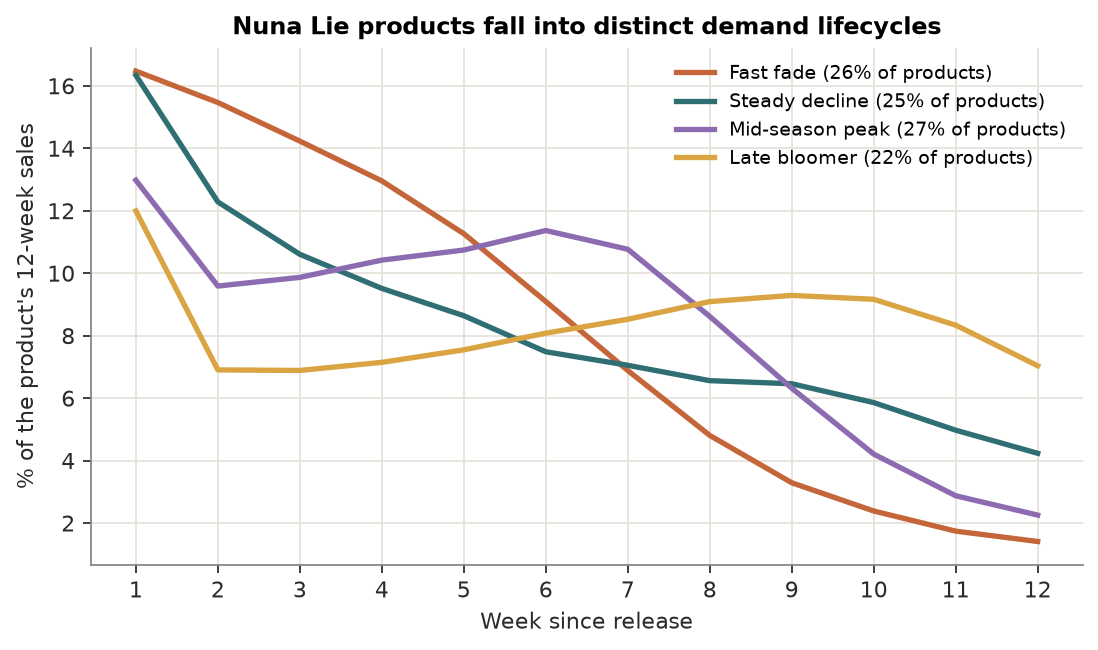

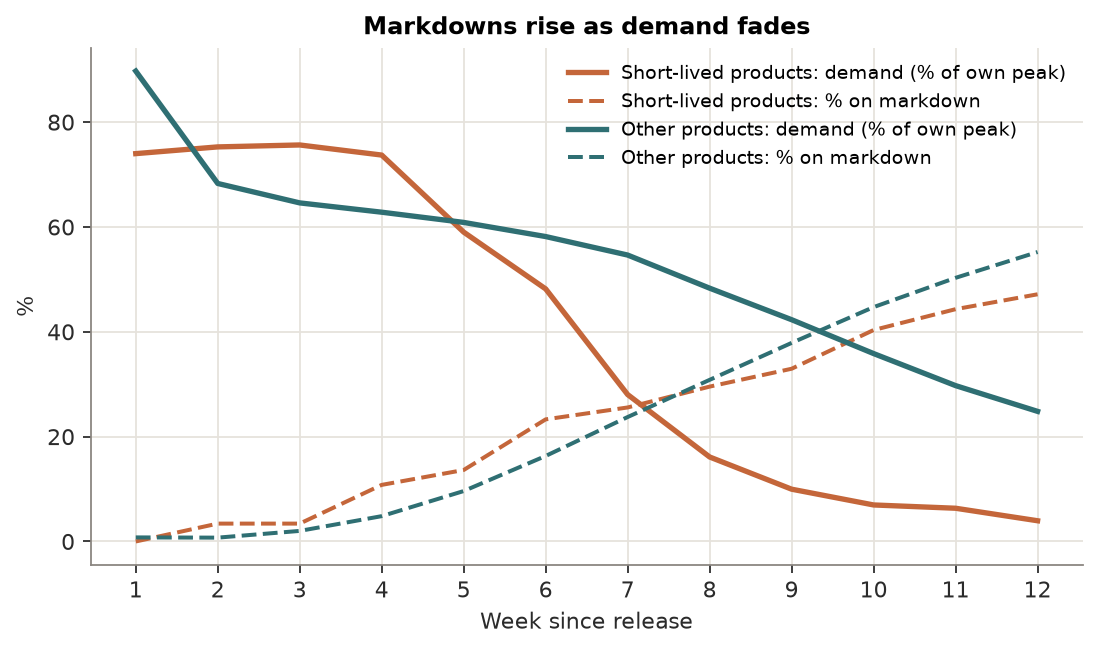

In [9]:
s = js("vis_lifecycle_summary")
am = s["all_products_markdown"]
say(f"""**Results**
- Silhouette by number of clusters: {", ".join(f"k={k}: {v:.3f}" for k, v in s["silhouette_by_k"].items())} → we use **k = {s["k_chosen"]}**
- Clusters: {", ".join(f"{n} {pct(v, 0)}" for n, v in s["cluster_shares"].items())}
- Short-lived products: **{pct(s["share_short_lived"])}** ({s["short_lived_products"]} of {s["products_in_sample"]:,}); median sell-through {pct(s["short_lived_sell_through_median"], 0)} vs {pct(s["other_sell_through_median"], 0)} for the others
- **{pct(am["marked_down_after_demand_halved"], 0)} of marked-down products were cut only after demand had halved**; demand at the first markdown was {pct(am["median_demand_at_markdown_vs_peak"], 0)} of peak (median)""")
fig("vis_cluster_silhouette", 500); fig("vis_lifecycle_clusters"); fig("vis_markdown_vs_demand")

## 3 · Predicting high leftover (before launch → after 2 weeks)

**What it does.** A product has *high leftover* if less than 60% of its stock sold within 12 weeks. We train on the 2017-18 seasons and test on the 2019 seasons, which the models never saw, at three stages:
- **Product only**: category, colour, fabric, season, price position in its category, release month.
- **+ buying plan**: number of shops and initial units per shop.
- **After 2 weeks**: plus the first two weeks of sales.

**Logistic regression**, a **decision tree** and **gradient boosting** each give the probability of high leftover. **ROC-AUC** measures how well they rank risky products (0.5 = guessing). **Odds ratios** (statsmodels logit) show which features raise or lower the risk.

**The algorithm (our code):**

In [10]:
from src import vis_risk_model as R
show(R.main, "models = {", "scores[(stage, name)] = s")   # three models at three stages
show(R.evaluate)
show(R.main, "formula = (", "lm = smf.logit")              # odds-ratio model

models = {
        "Logistic regression": lambda: LogisticRegression(C=0.5, max_iter=5000, class_weight="balanced"),
        "Decision tree (depth 4)": lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, class_weight="balanced",
                                                                  random_state=RANDOM_STATE),
        "Gradient boosting": lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced",
                                                                    random_state=RANDOM_STATE),
    }
    stages = {"Before launch: product only": NUM_A, "Before launch: product + buying plan": NUM_B,
              "After 2 weeks of sales": NUM_C}
    rows, scores = [], {}
    for stage, num in stages.items():
        for name, make in models.items():
            if stage == "After 2 weeks of sales" and name.startswith("Decision"):
                continue
            pipe = Pipeline([("pre", pre(num)), ("m", make())]).fit(tr[CATS + num], ytr)
            s = pipe.predict_proba(te[CATS + num])[:, 1]
            rows.append(evaluate(name, stage, yte, s))
            scores[(stage, name)] = s

def evaluate(name, stage, y, s):
    return {"model": name, "stage": stage, "roc_auc": float(roc_auc_score(y, s)), "pr_auc": float(average_precision_score(y, s)),
            "precision_top10pct": precision_at(y, s), "base_rate": float(y.mean())}

formula = (f"y ~ C(category, Treatment('{ref['category']}')) + C(color, Treatment('{ref['color']}')) "
               f"+ C(fabric, Treatment('{ref['fabric']}')) + C(season_type, Treatment('SS')) "
               "+ C(price_q, Treatment('Q2')) + C(depth_q, Treatment('Q2'))")
    lm = smf.logit(formula, data=o).fit(disp=False, maxiter=300)

In [11]:
R.main()   # run step 3

train 3450 (high-leftover rate 0.188)  test 1896 (0.104)


                     model                                 stage  roc_auc  pr_auc  precision_top10pct  base_rate
0      Logistic regression           Before launch: product only    0.627   0.144               0.153      0.104
1  Decision tree (depth 4)           Before launch: product only    0.624   0.146               0.169      0.104
2        Gradient boosting           Before launch: product only    0.676   0.169               0.153      0.104
3      Logistic regression  Before launch: product + buying plan    0.644   0.166               0.175      0.104
4  Decision tree (depth 4)  Before launch: product + buying plan    0.609   0.149               0.153      0.104
5        Gradient boosting  Before launch: product + buying plan    0.694   0.198               0.206      0.104
6      Logistic regression                After 2 weeks of sales    0.636   0.172               0.212      0.104
7        Gradient boosting                After 2 weeks of sales    0.713   0.235               

,model,stage,roc_auc,precision_top10pct
0,Logistic regression,Before launch: product only,0.627,0.153
1,Decision tree (depth 4),Before launch: product only,0.624,0.169
2,Gradient boosting,Before launch: product only,0.676,0.153
3,Logistic regression,Before launch: product + buying plan,0.644,0.175
4,Decision tree (depth 4),Before launch: product + buying plan,0.609,0.153
5,Gradient boosting,Before launch: product + buying plan,0.694,0.206
6,Logistic regression,After 2 weeks of sales,0.636,0.212
7,Gradient boosting,After 2 weeks of sales,0.713,0.270
8,Baseline: category rate,Baseline,0.571,0.153


,term,odds_ratio,ci_low,ci_high,p_value
1,color = yellow,1.533,1.040,2.259,0.031
3,fabric = scuba crepe,1.512,1.035,2.209,0.033
6,depth_q = Q4 deepest,1.296,1.047,1.603,0.017
8,price_q = Q4 priciest,1.272,1.023,1.580,0.030
37,fabric = rare fabric,0.679,0.510,0.903,0.008
40,category = sleeveless,0.540,0.378,0.773,0.001
41,season_type = AW,0.533,0.453,0.627,0.000
42,category = long dress,0.527,0.318,0.873,0.013
43,fabric = nice,0.364,0.238,0.559,0.000
44,category = patterned top,0.336,0.186,0.607,0.000


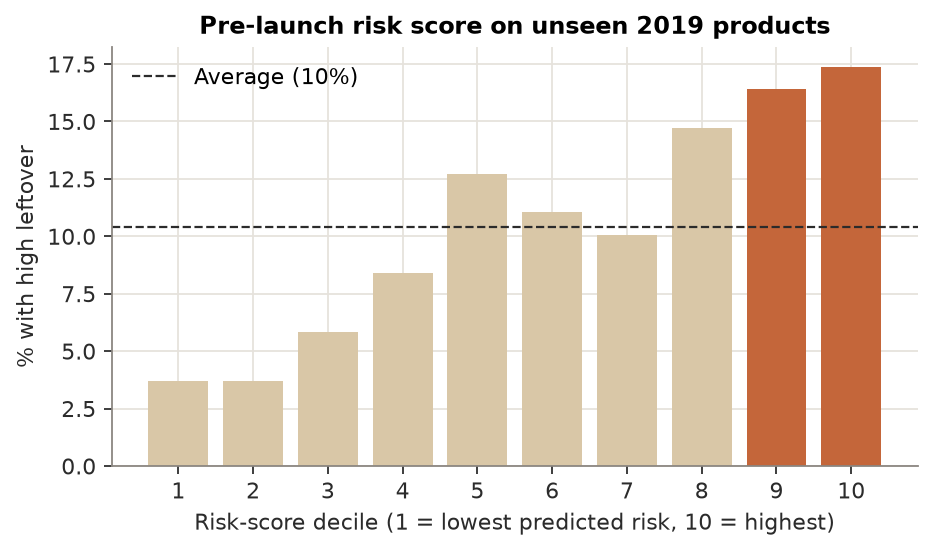

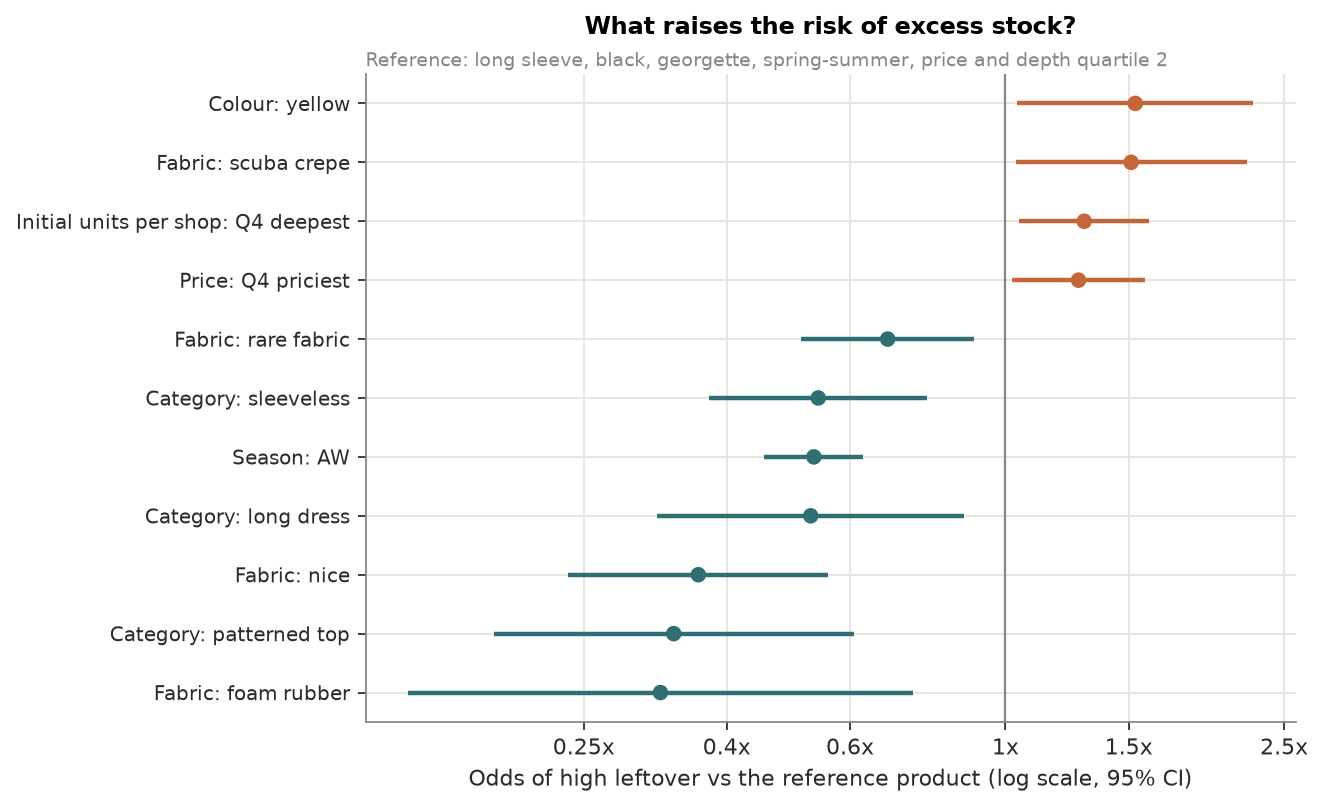

In [12]:
m = table("vis_risk_model_metrics")
display(m[["model", "stage", "roc_auc", "precision_top10pct"]])
o = table("vis_risk_odds_ratios")
display(o[o.p_value < 0.05].round(3))
fig("vis_risk_deciles", 600); fig("vis_risk_odds_ratios", 700)

## 4 · Who buys? (customer segmentation and CLTV)

**What it does.** The loyalty-card purchases (December 2016 to February 2020) are linked to the same products and shops. IDs that buy in more than 10 shops are shop cards, not people, and are excluded. For each customer we build **RFM features** (recency, purchase days, spend per basket, items per basket). Then:
- **K-means** groups similar customers, with the number of groups chosen by **silhouette score**.
- **CLTV** (customer lifetime value) = last-12-month spend × expected lifetime, with lifetime from 12-month retention (index units, since prices are normalised).
- **Spearman correlation** tests whether frequent customers buy more short-lived or marked-down products.

**The algorithm (our code):**

In [13]:
from src import vis_customers as CU
show(CU.purchases, "shops = c.groupby", "c = c[~c.customer.isin(cards)]")   # exclude shop cards
show(CU.customer_table)                                                     # RFM features per customer
show(CU.segment)                                                            # standardise + K-means + silhouette

shops = c.groupby("customer").retail.nunique()
    cards = shops[shops > CUSTOMER_MAX_SHOPS].index
    excluded_units = int(c[c.customer.isin(cards)].qty.sum())
    c = c[~c.customer.isin(cards)].copy()

def customer_table(c):
    c = c.assign(spend=c.qty * c.unit_price,
                 sl_units=np.where(c.short_lived.isna(), np.nan, c.qty * c.short_lived.fillna(False)),
                 hl_units=np.where(c.high_leftover.isna(), np.nan, c.qty * c.high_leftover.fillna(False)),
                 known_units=np.where(c.short_lived.isna(), 0, c.qty),
                 last12=c.data >= END - pd.DateOffset(years=1),
                 y1=(c.data >= Y1[0]) & (c.data < Y1[1]), y2=(c.data >= Y2[0]) & (c.data < Y2[1]))
    g = c.groupby("customer")
    t = pd.DataFrame({
        "first": g.data.min(), "last": g.data.max(), "purchase_days": g.day.nunique(), "units": g.qty.sum(),
        "spend": g.spend.sum(), "shops": g.retail.nunique(), "known_units": g.known_units.sum(),
        "short_lived_units": g.sl_units.sum(), "high_leftover_units": g.hl_units.sum(),
        "markdown_lines": g.markdown.sum(), "known_discount_lines": g.markdown.count(),
        "spend_last12m": c[c.last12].groupby("customer").spend.sum(),
        "active_y1": g.y1.any(), "active_y2": g.y2.any()}).fillna({"spend_last12m": 0})
    t["recency_days"] = (END - t["last"]).dt.days
    t["tenure_years"] = np.maximum((END - t["first"]).dt.days / 365.25, 1.0)
    t["purchases_per_year"] = t.purchase_days / t.tenure_years
    t["items_per_basket"] = t.units / t.purchase_days
    t["spend_per_basket"] = t.spend / t.purchase_days
    t["short_lived_units"] = t.short_lived_units.astype(float)
    t["high_leftover_units"] = t.high_leftover_units.astype(float)
    t["markdown_lines"] = t.markdown_lines.astype(float)
    t["short_lived_share"] = np.where(t.known_units >= 3, t.short_lived_units / t.known_units.clip(lower=1), np.nan)
    t["high_leftover_share"] = np.where(t.known_units >= 3, t.high_leftover_units / t.known_units.clip(lower=1), np.nan)
    t["markdown_share"] = np.where(t.known_discount_lines >= 3, t.markdown_lines / t.known_discount_lines.clip(lower=1), np.nan)
    t["freq_band"] = pd.cut(t.purchases_per_year, FREQ_BANDS, labels=FREQ_LABELS, right=False)
    return t.reset_index().sort_values("customer").reset_index(drop=True)

def segment(t):
    X = StandardScaler().fit_transform(np.column_stack([
        np.log1p(t.recency_days), np.log1p(t.purchase_days), np.log1p(t.spend_per_basket * 1000), np.log1p(t.items_per_basket)]))
    rng = np.random.default_rng(RANDOM_STATE)
    samp = rng.choice(len(X), size=20000, replace=False)
    scores, models = {}, {}
    for k in range(3, 8):
        km = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, batch_size=8192, n_init=5).fit(X)
        scores[k], models[k] = float(silhouette_score(X[samp], km.labels_[samp])), km
    k_best = max(scores, key=scores.get)
    for k in (4, 5, 6):  # prefer 4-6 segments when within 0.02 of the best: easier to act on
        if scores[k] >= scores[k_best] - 0.02:
            k_best = k
            break
    return models[k_best].labels_, scores, k_best

In [14]:
CU.main()   # run step 4

   segment_id                                segment  customers  purchase_days_median  recency_median  purchases_per_year_median  items_per_basket_mean  spend_per_basket_median  spend_per_customer_mean  short_lived_share_mean  markdown_share_mean  high_leftover_share_mean  retention_12m  spend_last12m_mean  share_of_units  share_of_spend  share_of_customers  expected_lifetime_years  cltv_index
0           3                       Frequent, active      99879                 6.000          93.000                      2.982                  1.990                    0.146                    1.231                   0.040                0.283                     0.182          0.891               0.484           0.498           0.486               0.152                    5.000       2.421
1           1                         Repeat, active     113140                 2.000          56.000                      1.000                  1.432                    0.121                    0.233     

,segment,share_of_customers,share_of_units,share_of_spend,markdown_share_mean,short_lived_share_mean,cltv_index
0,"Frequent, active",0.152,0.498,0.486,0.283,0.040,2.421
1,"Repeat, active",0.172,0.094,0.104,0.285,0.041,0.945
2,"One-time, lapsing, multi-item baskets",0.292,0.275,0.276,0.237,0.038,0.185
3,"One-time, lapsing, single items",0.384,0.134,0.134,0.239,0.040,0.041


,freq_band,customers,markdown_share,short_lived_share
0,Once a year or less,470297,0.233,0.038
1,2-4 times a year,165306,0.272,0.041
2,5-11 times a year,20651,0.303,0.041
3,Monthly or more,1559,0.365,0.042


- 657,813 customers; the top 20% buy **61%** of units
- Spearman, buying frequency vs markdown share: ρ = 0.17; vs short-lived share: ρ = 0.19

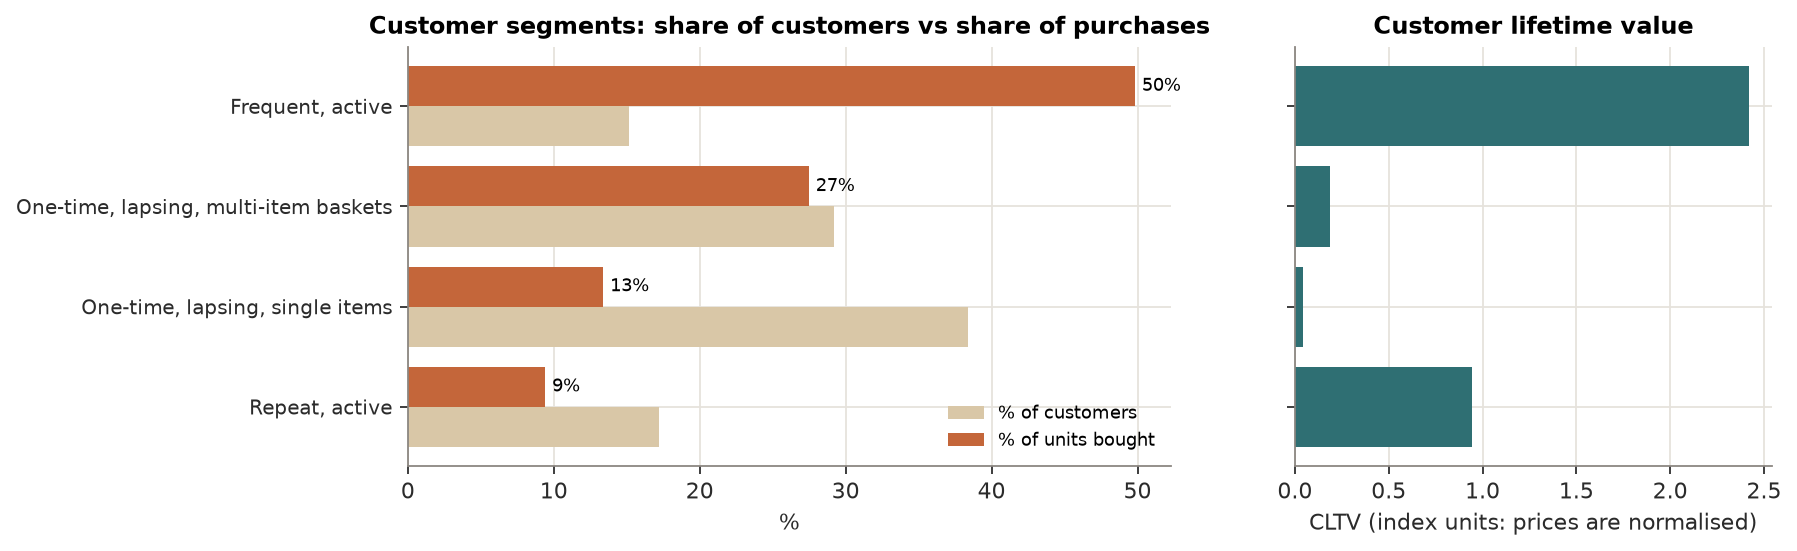

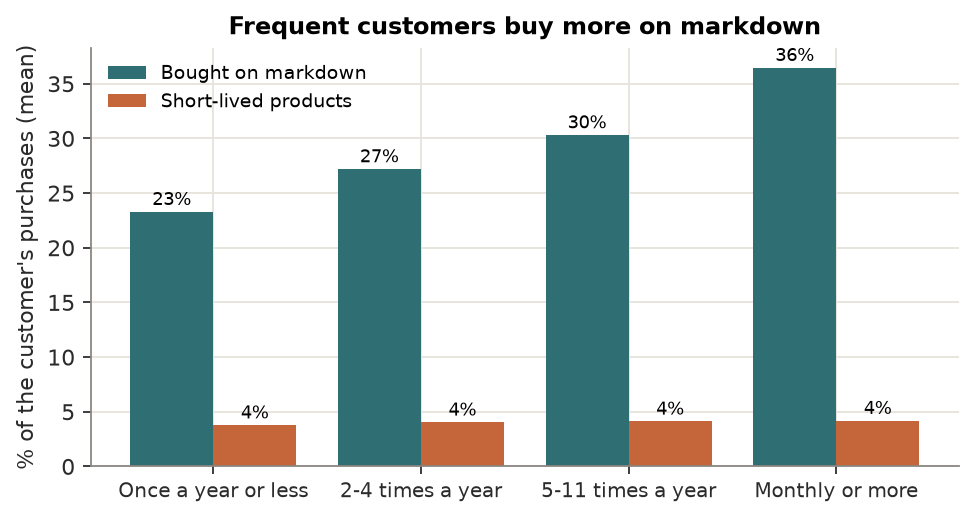

In [15]:
display(table("vis_customer_segments")[["segment", "share_of_customers", "share_of_units", "share_of_spend",
                                        "markdown_share_mean", "short_lived_share_mean", "cltv_index"]])
display(table("vis_customers_by_frequency")[["freq_band", "customers", "markdown_share", "short_lived_share"]])
c = js("vis_customers_summary")
say(f"""- {c["customers"]:,} customers; the top 20% buy **{pct(c["share_units_top20pct_customers"], 0)}** of units
- Spearman, buying frequency vs markdown share: ρ = {c["spearman_frequency_vs_markdown_share"]["rho"]:.2f}; vs short-lived share: ρ = {c["spearman_frequency_vs_short_lived_share"]["rho"]:.2f}""")
fig("vis_customer_segments"); fig("vis_customers_by_frequency", 600)

## 5 · Market trends

**What it does.** From weekly loyalty-card purchases we compute a **4-week moving average**, a **linear trendline** and a **seasonal index** (each month's average week ÷ the overall average week). We also test whether **Google Trends** search interest improves the forecasts.

**The algorithm (our code):**

In [16]:
from src import trends as T
show(T.vis_demand)
show(T.gt_value)
T.main()   # run step 5

def vis_demand():
    c = pd.read_csv(VIS_RAW / "customer_data.csv", parse_dates=["data"])
    shops = c.groupby("customer").retail.nunique()
    c = c[~c.customer.isin(shops[shops > CUSTOMER_MAX_SHOPS].index)]
    c = c[(c.data >= START) & (c.data < END)]
    w = c.set_index("data").qty.resample("W-MON", label="left", closed="left").sum().rename("units").reset_index()
    w = w.rename(columns={"data": "week"})
    w = w[(w.week >= START) & (w.week + pd.Timedelta(days=6) < END)].reset_index(drop=True)  # full weeks only
    w["ma4"] = w.units.rolling(4, center=True).mean()
    t = (w.week - w.week.min()).dt.days / 7
    slope, intercept = np.polyfit(t, w.units, 1)
    w["trendline"] = intercept + slope * t

    def window(y):  # same calendar weeks, June-December
        m = (w.week >= pd.Timestamp(f"{y}-06-01")) & (w.week < pd.Timestamp(f"{y}-12-24"))
        return w.loc[m, "units"].sum()
    yr = w[(w.week >= pd.Timestamp("2018-01-01")) & (w.week < pd.Timestamp("2019-12-24"))].copy()
    yr["month"] = yr.week.dt.month
    idx = (yr.groupby("month").units.mean() / yr.units.mean()).rename("seasonal_index")
    res = {
        "window": f"{w.week.min():%d %b %Y} - {w.week.max():%d %b %Y}", "weeks": int(len(w)),
        "trend_slope_units_per_week": float(slope), "trend_pct_per_year_of_mean": float(slope * 52 / w.units.mean()),
        "yoy_growth_jun_dec": float(window(2019) / window(2018) - 1),
        "seasonal_peak_month": int(idx.idxmax()), "seasonal_peak_index": float(idx.max()),
        "seasonal_trough_month": int(idx.idxmin()), "seasonal_trough_index": float(idx.min()),
    }
    save_table(w[["week", "units", "ma4", "trendline"]], "vis_weekly_demand")
    save_table(idx.reset_index(), "vis_seasonal_index")
    return w, idx, res

def gt_value():
    """Does market interest (Google Trends) help? (a) before launch: total 12-week sales per product;
    (b) after two weeks: from the week-2 forecasting comparison in vis_forecast."""
    meta, S, D, Dsc, _ = vf.load()
    prod, Sp, Dp, dscp, idx, codes = vf.product_table(meta, S, D, Dsc)
    prod["initial_stock"] = Dp[:, 0]
    prod["log_initial_stock"] = np.log1p(prod.initial_stock)
    prod["y"] = Sp.sum(1)
    for c in ("category", "color", "fabric"):
        prod[c] = prod[c].astype("category")
    gt = [c for c in prod if c.startswith("gt_")]
    base = ["price", "n_shops", "release_month", "log_initial_stock"]
    tr, te = prod[prod.season.isin(vf.TRAIN)], prod[prod.season.isin(vf.TEST)]
    out = {}
    for name, feats in (("with Google Trends", base + gt), ("without Google Trends", base)):
        m = HistGradientBoostingRegressor(loss="poisson", max_iter=500, learning_rate=0.05,
                                          categorical_features="from_dtype", random_state=RANDOM_STATE)
        m.fit(tr[feats + ["category", "color", "fabric"]], tr.y)
        f = m.predict(te[feats + ["category", "color", "fabric"]])
        out[name] = {"wape": float(np.abs(f - te.y).sum() / te.y.sum()),
                     "spearman": float(spearmanr(f, te.y)[0])}
    fm = pd.read_csv(TAB / "vis_forecast_metrics.csv")
    fm = fm[fm.group == "All products"].set_index("model")
    week2 = {"with Google Trends": float(fm.loc["Gradient boosting + Google Trends", "weekly_wape"]),
             "without Google Trends": float(fm.loc["Gradient boosting (no Google Trends)", "weekly_wape"])}
    return {"prelaunch_total_sales": out, "week2_weekly_wape": week2}

{'window': '05 Jun 2017 - 23 Dec 2019', 'weeks': 134, 'trend_slope_units_per_week': 73.32963503285565, 'trend_pct_per_year_of_mean': 0.18855195295690838, 'yoy_growth_jun_dec': 0.4133049448629236, 'seasonal_peak_month': 7, 'seasonal_peak_index': 1.4303256186754834, 'seasonal_trough_month': 3, 'seasonal_trough_index': 0.726076363272035, 'google_trends': {'prelaunch_total_sales': {'with Google Trends': {'wape': 0.3360854819695176, 'spearman': 0.9904616385868514}, 'without Google Trends': {'wape': 0.33492572013815725, 'spearman': 0.9904874879624259}}, 'week2_weekly_wape': {'with Google Trends': 0.393808893212227, 'without Google Trends': 0.3885848542487297}}}


,month,seasonal_index
0,1,1.104
1,2,0.860
2,3,0.726
3,4,0.838
4,5,0.894
5,6,1.075
6,7,1.430
7,8,1.019
8,9,0.838
9,10,0.899


- Peak month: **July** (index 1.43); low month: March (index 0.73)
- June-December 2019 vs 2018: 41% (includes customers joining the card)
- Google Trends, before launch: WAPE 33.6% with vs 33.5% without; at week 2: 39.4% vs 38.9% → **no improvement**

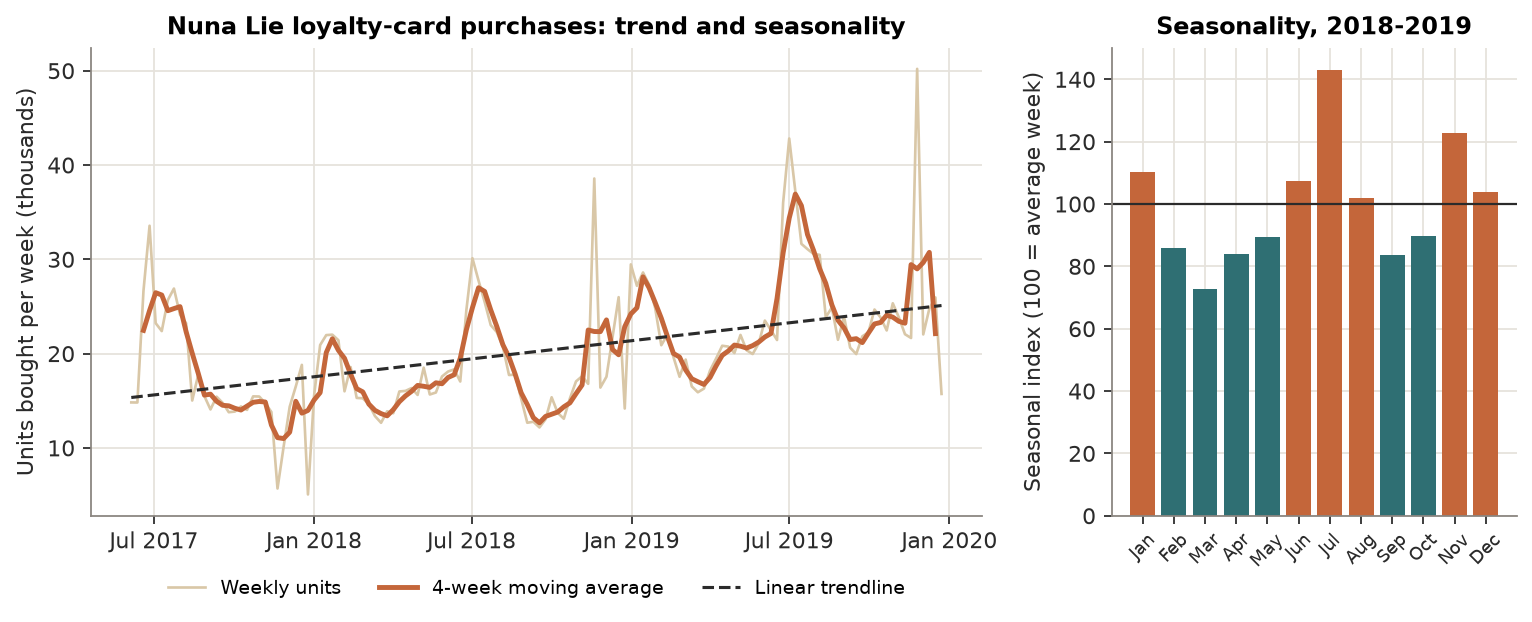

In [17]:
tr = js("trends_summary")
gt = tr["google_trends"]
display(table("vis_seasonal_index"))
import calendar
say(f"""- Peak month: **{calendar.month_name[tr["seasonal_peak_month"]]}** (index {tr["seasonal_peak_index"]:.2f}); low month: {calendar.month_name[tr["seasonal_trough_month"]]} (index {tr["seasonal_trough_index"]:.2f})
- June-December 2019 vs 2018: {pct(tr["yoy_growth_jun_dec"], 0)} (includes customers joining the card)
- Google Trends, before launch: WAPE {pct(gt["prelaunch_total_sales"]["with Google Trends"]["wape"])} with vs {pct(gt["prelaunch_total_sales"]["without Google Trends"]["wape"])} without; at week 2: {pct(gt["week2_weekly_wape"]["with Google Trends"])} vs {pct(gt["week2_weekly_wape"]["without Google Trends"])} → **no improvement**""")
fig("vis_demand_trend")

## 6 · How to prove it in real shops: pilot design (power analysis)

**What it does.** We plan a randomised pilot: half the flagged products follow the week-2 rule and half don't. A **power analysis** (two-sample t-test, 80% power, 5% significance) tells us how many products, or shops, each group needs.

power = TTestIndPower()
    rows = []
    for frac in (0.5, 0.75, 1.0):
        d_raw, d_adj = effect * frac / sd, effect * frac / sd_adj
        rows.append({"effect_as_share_of_simulated": frac, "effect_pp": effect * frac * 100,
                     "shops_per_arm_simple": int(np.ceil(power.solve_power(d_raw, alpha=0.05, power=0.8))),
                     "shops_per_arm_ancova": int(np.ceil(power.solve_power(d_adj, alpha=0.05, power=0.8)))})

{'base_leftover_share_test_shops_mean': 0.30532743177052707, 'expected_effect_pp': 2.817043342222237, 'between_shop_sd_pp': 4.639063890307797, 'prior_season_correlation': 0.1559423627614186, 'sd_after_ancova_pp': np.float64(4.582310307676588), 'shops_per_arm_full_effect_simple': 44, 'shops_per_arm_full_effect_ancova': 43, 'shops_per_arm_half_effect_ancova': 168, 'product_design_effect_pp': 14.055199948554725, 'product_design_sd_pp': 9.123789672344367, 'products_per_arm_full_effect': 8, 'products_per_arm_half_effect': 28, 'flagged_products_per_season': 96, 'shops_available_per_season': 96, 'share_shops_improving': 0.9850746268656716}
                       design  effect_as_share_of_simulated  effect_pp  units_per_arm  units_per_arm_ancova
0             Randomise shops                         0.500      1.409            172               168.000
1             Randomise shops                         0.750      2.113             77                75.000
2             Randomise shops      

,design,effect_as_share_of_simulated,effect_pp,units_per_arm,units_per_arm_ancova
0,Randomise shops,0.500,1.409,172,168.000
1,Randomise shops,0.750,2.113,77,75.000
2,Randomise shops,1.000,2.817,44,43.000
3,Randomise flagged products,0.500,7.028,28,NaN
4,Randomise flagged products,0.750,10.541,13,NaN
5,Randomise flagged products,1.000,14.055,8,NaN


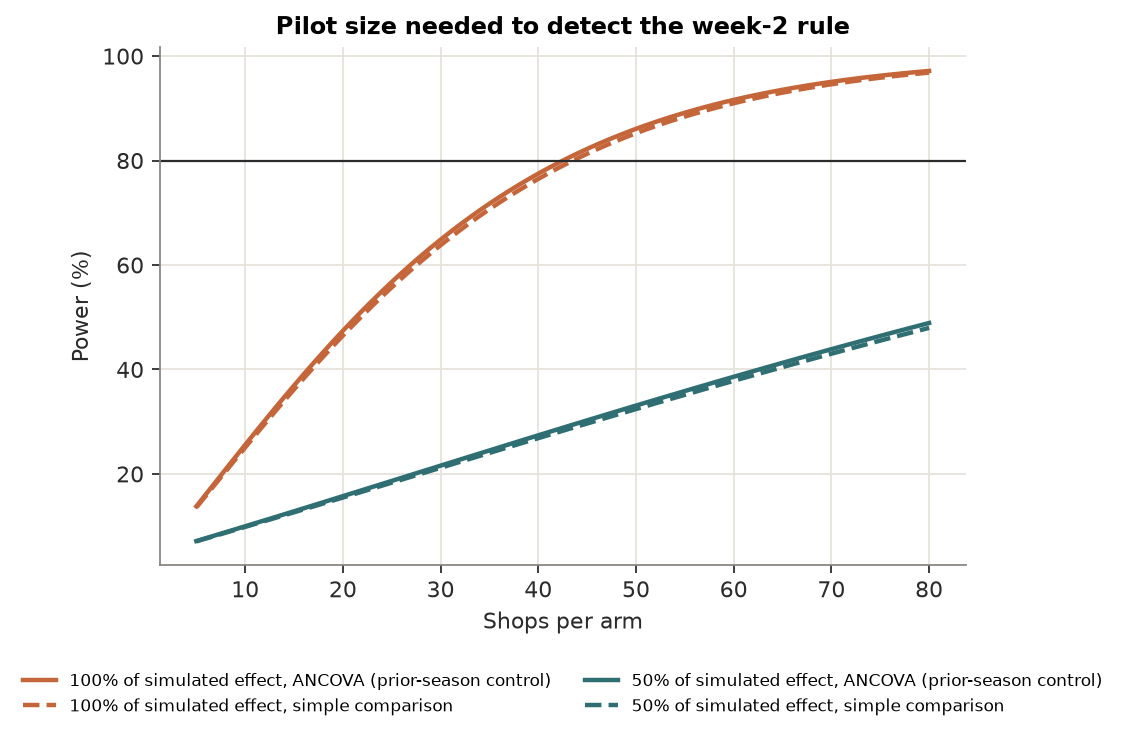

In [18]:
from src import pilot_design as P
show(P.main, "power = TTestIndPower()", "shops_per_arm_ancova")
P.main()   # run step 6
display(table("pilot_sample_size"))
fig("pilot_power", 600)

## 7 · Financial statements built from the data

**What it does.** Nuna Lie publishes no accounts, so we build season statements from the data itself: revenue after discounts, **markdown cost**, the value of **unsold stock**, **inventory turnover**, **days of inventory** and **gross margin**. Prices are normalised, so money is in index units (the ratios are unaffected). Unit cost is not in the data, so margins use an assumed cost of 40%, 50% or 60% of full price. We then cost the week-2 rule.

In [19]:
from src import vis_financials as F
show(F.statement)
F.main()   # run step 7

def statement(price, S, D, Dsc):
    """Inventory statement for a set of product-shops (rows). Money in index units."""
    avail, end = vf.stock_path(D, S)
    left = np.maximum(end[:, -1], 0)
    fp_sold = (price[:, None] * S).sum()
    net = (price[:, None] * (1 - Dsc) * S).sum()
    fp_deliv = (price[:, None] * D).sum()
    avg_stock = np.maximum(end, 0).sum(0).mean()          # average end-of-week stock, units
    out = {"units_delivered": D.sum(), "units_sold": S.sum(), "units_unsold": left.sum(),
           "full_price_value_delivered": fp_deliv, "full_price_value_sold": fp_sold, "net_revenue": net,
           "markdown_cost": fp_sold - net, "closing_stock_value": (price * left).sum()}
    out.update({"sell_through": out["units_sold"] / out["units_delivered"],
                "markdown_rate": out["markdown_cost"] / fp_sold,
                "stock_to_sales": out["closing_stock_value"] / net,
                "inventory_turnover_12w": out["units_sold"] / avg_stock,
                "days_of_inventory": avg_stock / (out["units_sold"] / DAYS)})
    for c in COST_RATIOS:
        k = int(c * 100)
        out[f"gross_margin_cost{k}"] = (net - c * fp_sold) / net                     # on goods sold
        out[f"margin_after_unsold_cost{k}"] = (net - c * fp_deliv) / net            # if unsold stock is not recovered
    return out

        season  units_delivered    units_sold  units_unsold  full_price_value_delivered  full_price_value_sold  net_revenue  markdown_cost  closing_stock_value  sell_through  markdown_rate  stock_to_sales  inventory_turnover_12w  days_of_inventory  gross_margin_cost40  margin_after_unsold_cost40  gross_margin_cost50  margin_after_unsold_cost50  gross_margin_cost60  margin_after_unsold_cost60
0         SS17      290,480.000   195,046.000    96,170.000                  20,778.973             13,751.979   11,902.367      1,849.612            7,058.586         0.671          0.134           0.593                   1.698             49.457                0.538                       0.302                0.422                       0.127                0.307                      -0.047
1         AW17      347,832.000   244,412.000   104,512.000                  30,280.492             21,202.725   19,176.071      2,026.653            9,163.687         0.703          0.096           0.478      

,season,sell_through,markdown_rate,stock_to_sales,inventory_turnover_12w,days_of_inventory,gross_margin_cost50,margin_after_unsold_cost50
0,SS17,0.671,0.134,0.593,1.698,49.457,0.422,0.127
1,AW17,0.703,0.096,0.478,1.903,44.137,0.447,0.210
2,SS18,0.672,0.104,0.556,1.824,46.042,0.442,0.165
3,AW18,0.673,0.095,0.540,1.808,46.471,0.448,0.178
4,SS19,0.692,0.098,0.489,1.881,44.655,0.446,0.202
5,AW19,0.701,0.094,0.487,1.855,45.295,0.448,0.206
6,All seasons,0.686,0.101,0.516,1.833,45.816,0.444,0.187


- Week-2 rule, 2019 seasons: revenue -0.7%, gross profit after unsold stock 3.5% (cost 40%), 8.7% (cost 50%), 51.7% (cost 60%)
- Gross profit rises whenever unit cost is above **13.8%** of full price

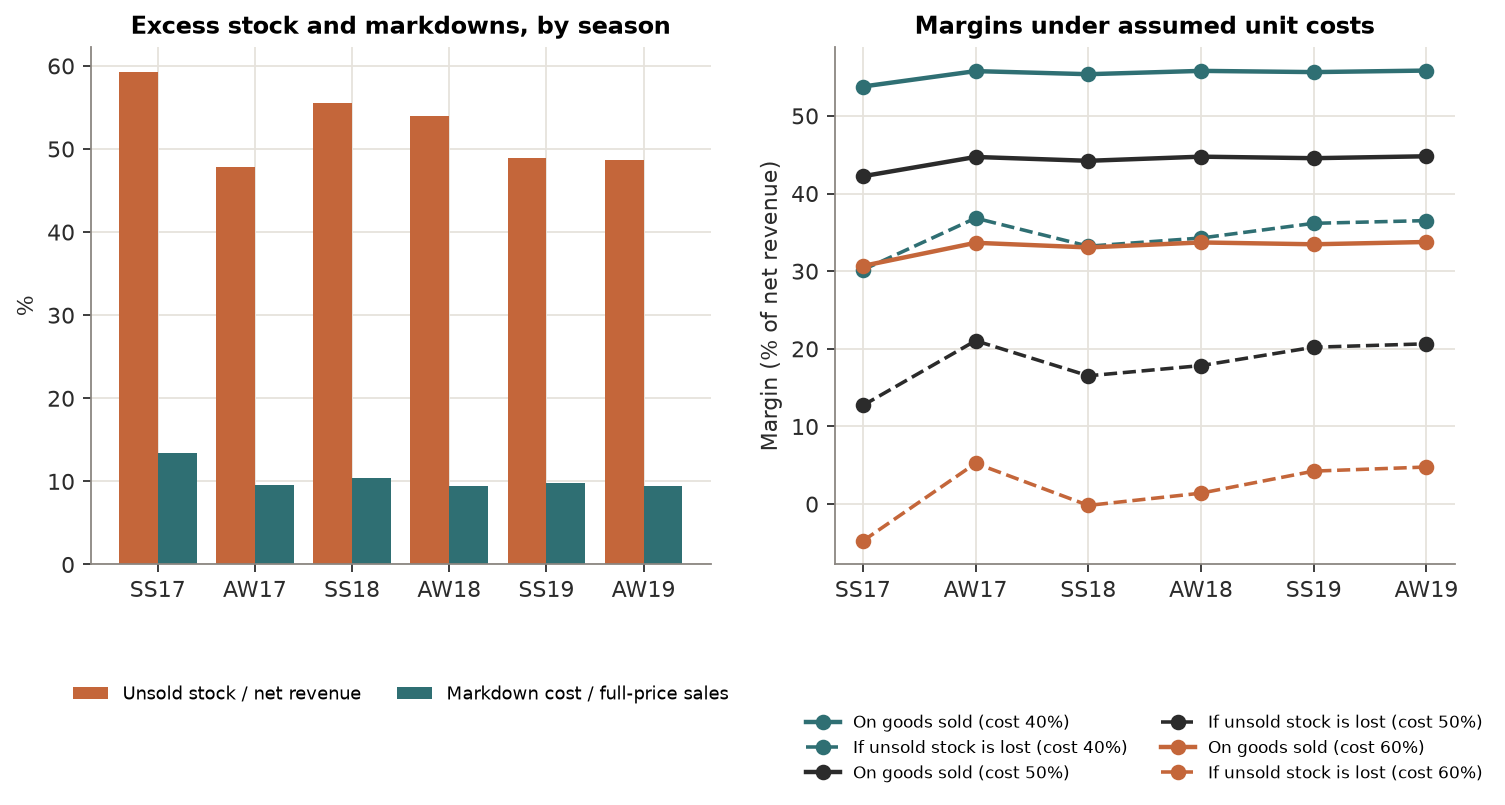

In [20]:
display(table("vis_financial_statement")[["season", "sell_through", "markdown_rate", "stock_to_sales", "inventory_turnover_12w",
                                          "days_of_inventory", "gross_margin_cost50", "margin_after_unsold_cost50"]])
fs = js("vis_financials_summary")
say(f"""- Week-2 rule, 2019 seasons: revenue {pct(fs["policy_revenue_change"])}, gross profit after unsold stock {", ".join(f"{pct(v)} (cost {k[4:]}%)" for k, v in fs["policy_gross_profit_change"].items())}
- Gross profit rises whenever unit cost is above **{pct(fs["breakeven_cost_to_price"])}** of full price""")
fig("vis_financial_statement")

## 8 · Consumer survey: conjoint analysis and shopper groups

**What it does.** We use the real responses to our Google Form.
- **Conjoint analysis**: each person rated 8 garment options that differ in price, style, lifespan and a sustainability label. An **OLS regression on ratings demeaned within each person** (respondent fixed effects, cluster-robust errors) gives each feature's effect. Dividing by the price effect gives **willingness to pay**, with a **bootstrap** confidence interval.
- **K-means** groups respondents by their purchase motives.
- **Spearman correlation**: does trend or discount buying go with shopping frequency or with age? A group-level comparison with Nuna Lie's customers uses the same frequency bands.

**The algorithm (our code):**

In [21]:
from src import survey_analysis as SA
show(SA.conjoint)
show(SA.bridge_with_vis)
desc = SA.run()   # run step 8

def conjoint(d, design, seed=RANDOM_STATE):
    """Rating-based conjoint on an orthogonal 2^(4-1) design (8 profiles per respondent).
    Respondent fixed effects via within-respondent demeaning; cluster-robust CIs by respondent.
    Straight-liners (all 8 ratings equal) carry no preference information and are excluded."""
    cj = d[CONJOINT]
    keep = cj.notna().all(axis=1) & (cj.nunique(axis=1) > 1)
    Y = cj[keep].to_numpy(float)                      # respondents x 8, columns = P1..P8
    Yd = Y - Y.mean(1, keepdims=True)
    long = pd.DataFrame(Yd, columns=design.profile).assign(rid=np.arange(len(Y))).melt(
        id_vars="rid", var_name="profile", value_name="rating_dm").merge(design, on="profile")
    m = smf.ols("rating_dm ~ " + " + ".join(ATTRS), data=long).fit(cov_type="cluster", cov_kwds={"groups": long.rid})
    pooled = pd.DataFrame({"attribute": ATTRS, "label": [ATTR_NAMES[a] for a in ATTRS],
                           "part_worth": m.params[ATTRS].values, "ci_low": m.conf_int().loc[ATTRS, 0].values,
                           "ci_high": m.conf_int().loc[ATTRS, 1].values, "p_value": m.pvalues[ATTRS].values})

    X = np.column_stack([np.ones(8), design[ATTRS].to_numpy(float)])
    P = np.linalg.pinv(X)                              # 5 x 8
    ind = Yd @ P.T                                     # individual part-worths (same as per-person OLS)
    imp = np.abs(ind[:, 1:]) / np.abs(ind[:, 1:]).sum(1, keepdims=True)
    importance = pd.Series(imp.mean(0), index=["Price", "Style (trendy)", "Lifespan", "Sustainability label"])

    def wtp_from(beta):  # beta columns: intercept, price, trendy, long_life, certified
        per_rs = -beta[..., 1] / PRICE_GAP_RS
        with np.errstate(divide="ignore", invalid="ignore"):
            return {a: np.where(per_rs > 0, beta[..., j] / per_rs, np.nan) for j, a in ((2, "trendy"), (3, "long_life"), (4, "certified"))}

    beta = Yd.mean(0) @ P.T
    wtp = {a: float(v) for a, v in wtp_from(beta).items()}
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(Yd), (BOOT, len(Yd)))
    bb = Yd[idx].mean(1) @ P.T
    wb = wtp_from(bb)
    wtp_ci = {a: [float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))] for a, v in wb.items()}
    return pooled, importance, wtp, wtp_ci, int(len(Y))

def bridge_with_vis(d):
    """Group-level comparison (never person-level) with Nuna Lie loyalty customers, by the same buying-frequency bands."""
    out = {}
    pf = TAB / "vis_customers_by_frequency.csv"
    if pf.exists():
        vf_ = pd.read_csv(pf).set_index("freq_band")[["customers", "short_lived_share", "markdown_share"]]
        vf_.columns = ["vis_customers", "vis_short_lived_share", "vis_markdown_share"]
        sv = d.groupby("Q5").agg(respondents=("Q5", "size"), trend_influence=("Q8a", "mean"),
                                 trend_4or5=("Q8a", lambda s: (s >= 4).mean()), discount_influence=("Q8b", "mean"),
                                 buys_fast_fashion=("buys_fast_fashion", "mean"))
        out["frequency"] = (sv.join(vf_, how="left").reindex([b for b in ORDER["Q5"] if b in sv.index])
                              .reset_index().rename(columns={"Q5": "freq_band"}))
    return out

{
 "quality": {
  "rows_in_file": 122,
  "consented": 122,
  "did_not_consent": 0,
  "duplicate_answer_rows": 0,
  "first_response": "2026-09-27 21:14:48",
  "last_response": "2026-10-10 22:07:00",
  "form_versions": {
   "v2 edited": 100,
   "v1 original": 22
  },
  "unmapped": {},
  "q9_unanswered": 17,
  "free_text_comments_not_shown": 6,
  "conjoint_incomplete": 0,
  "conjoint_all_same_rating_excluded": 1,
  "margin_of_error_95_for_a_share": 0.08872503112166816
 },
 "source_file": "survey_responses_2026-10-10.csv",
 "respondents": 122,
 "share_age_18_24": 0.7377049180327869,
 "share_students": 0.48360655737704916,
 "share_buys_fast_fashion": 0.680327868852459,
 "share_buys_second_hand": 0.05737704918032787,
 "motive_means_1to5": {
  "Trend": 3.040983606557377,
  "Discount": 3.942622950819672,
  "Novelty": 3.401639344262295,
  "Quality": 3.7540983606557377,
  "Environment": 2.7295081967213113
 },
 "motive_share_4or5": {
  "Trend": 0.4098360655737705,
  "Discount": 0.6967213114754098

,attribute,label,part_worth,ci_low,ci_high,p_value
0,price_high,"Price Rs 1,499 (vs Rs 799)",-1.095,-1.330,-0.860,0.000
1,trendy,Trendy (vs timeless),0.831,0.527,1.134,0.000
2,long_life,Lasts 3+ years (vs 1 season),1.665,1.312,2.019,0.000
3,certified,Certified sustainable (vs no label),1.153,0.884,1.422,0.000


- Importance: Price 23%, Style (trendy) 24%, Lifespan 31%, Sustainability label 21%
- Willingness to pay for a 3+ year lifespan: Rs 1,065 (95% CI 775-1,450); stated preference, values above the Rs 700 tested gap are extrapolation
- Trend influence vs buying frequency: ρ = 0.28 (p = 0.002); vs age: ρ = -0.12 (p = 0.176)

,name,respondents,Trend,Discount,Novelty,Quality,Environment,keep_years
0,Novelty & Trend-driven,58,3.776,4.379,4.086,3.500,1.828,1.948
1,Environment & Quality-driven,34,3.206,3.265,3.206,4.294,4.324,2.360
2,Low-involvement,30,1.433,3.867,2.300,3.633,2.667,2.867


,freq_band,respondents,trend_influence,trend_4or5,discount_influence,buys_fast_fashion,vis_customers,vis_short_lived_share,vis_markdown_share
0,Once a year or less,6,2.167,0.333,3.167,0.667,470297,0.038,0.233
1,2-4 times a year,34,2.618,0.176,3.794,0.676,165306,0.041,0.272
2,5-11 times a year,42,3.143,0.500,4.048,0.714,20651,0.041,0.303
3,Monthly or more,40,3.425,0.525,4.075,0.650,1559,0.042,0.365


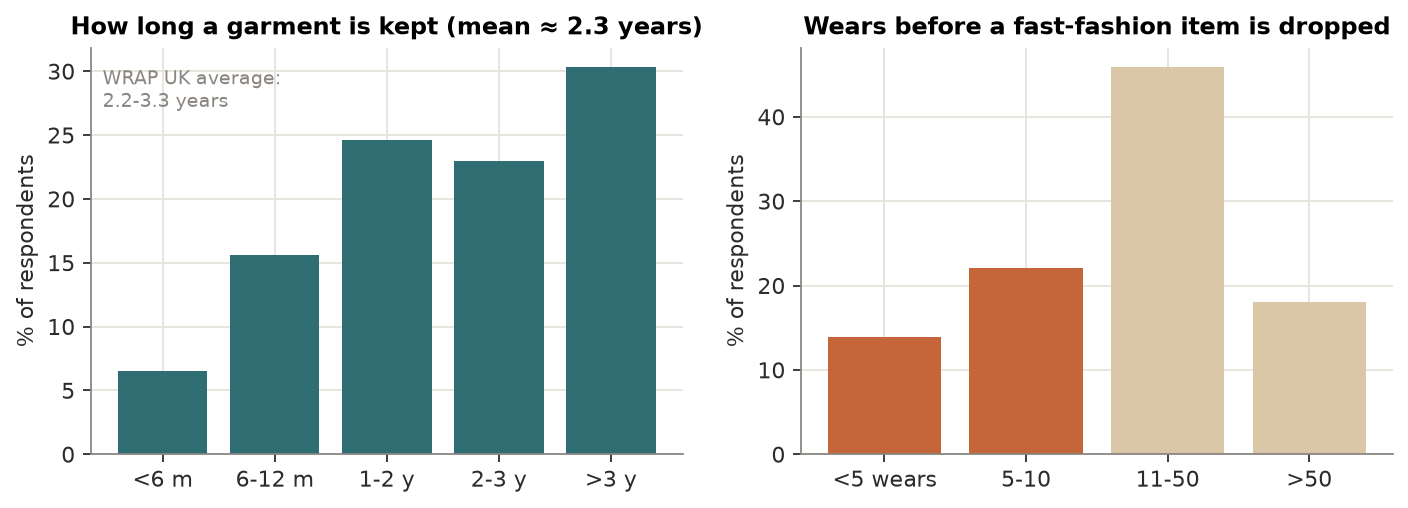

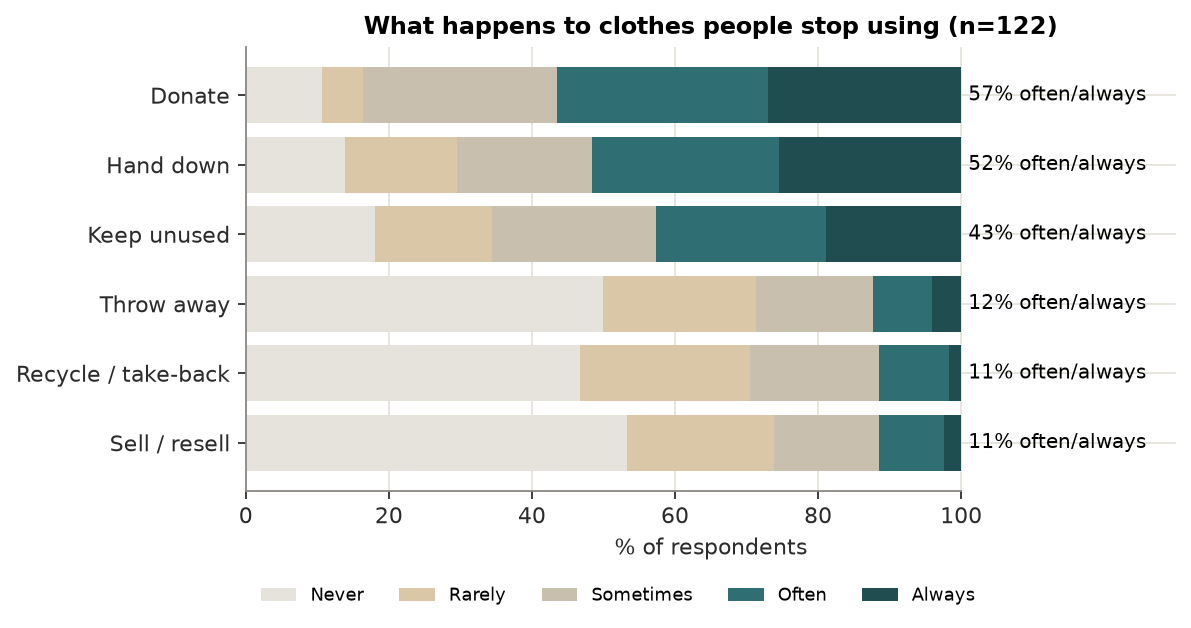

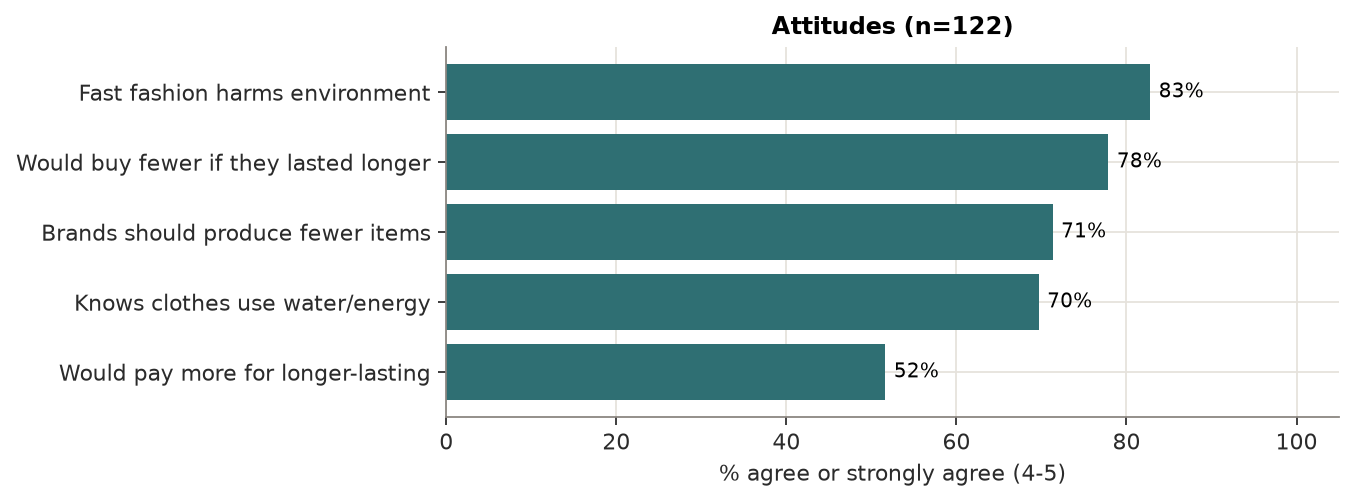

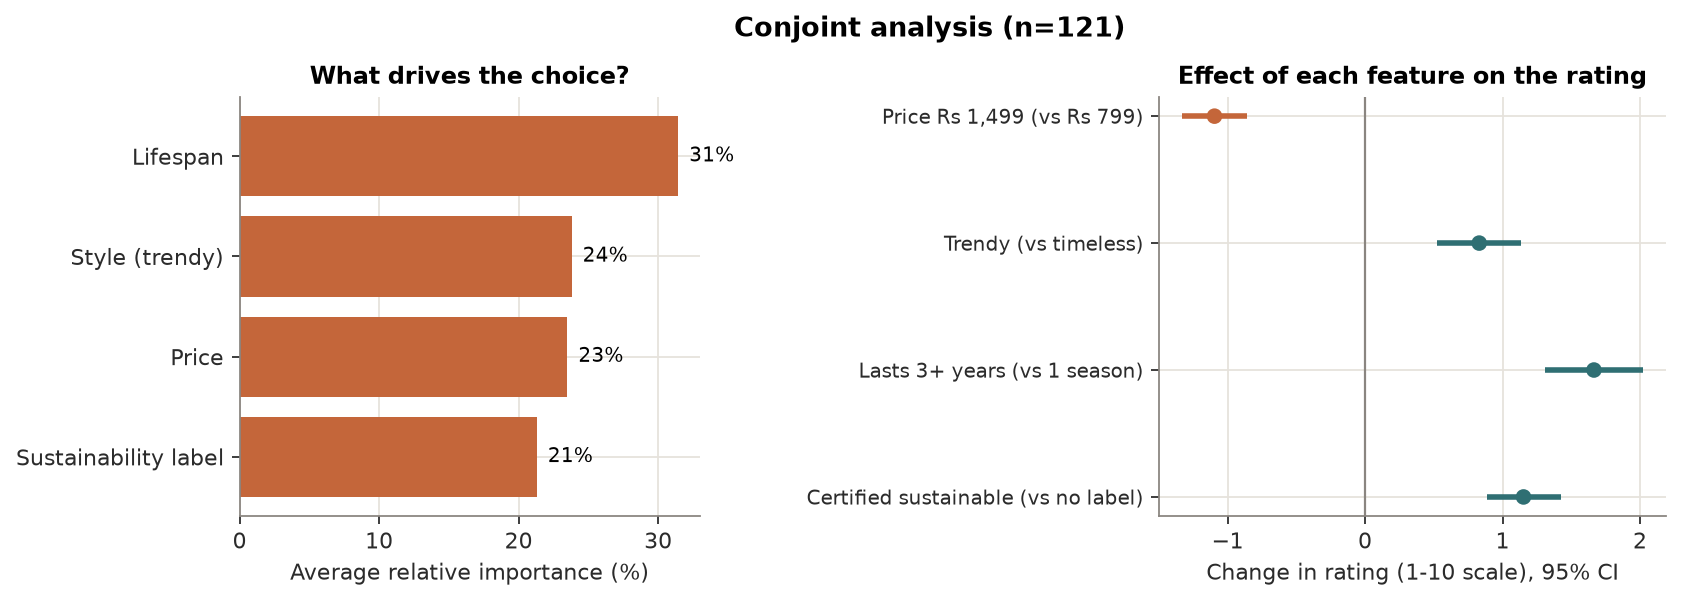

In [22]:
display(table("survey_conjoint_partworths"))
say(f"""- Importance: {", ".join(f"{k} {pct(v, 0)}" for k, v in desc["conjoint_importance"].items())}
- Willingness to pay for a 3+ year lifespan: Rs {desc["wtp_rs"]["long_life"]:,.0f} (95% CI {desc["wtp_rs_ci95"]["long_life"][0]:,.0f}-{desc["wtp_rs_ci95"]["long_life"][1]:,.0f}); stated preference, values above the Rs 700 tested gap are extrapolation
- Trend influence vs buying frequency: ρ = {desc["rank_corr_frequency_vs_trend"]["rho"]:.2f} (p = {desc["rank_corr_frequency_vs_trend"]["p_value"]:.3f}); vs age: ρ = {desc["rank_corr_age_vs_trend"]["rho"]:.2f} (p = {desc["rank_corr_age_vs_trend"]["p_value"]:.3f})""")
display(table("survey_segments")[["name", "respondents", "Trend", "Discount", "Novelty", "Quality", "Environment", "keep_years"]])
display(table("survey_vis_bridge_by_frequency"))
for n in ("survey_lifetime", "survey_disposal", "survey_attitudes", "survey_conjoint_importance"):
    fig(n)

## Summary: the headline numbers

Every result above is also written to `reports/claims_register.csv`. These are the numbers in our slides.

In [23]:
claims = pd.read_csv("reports/claims_register.csv").set_index("claim_id")
keys = ["vis_leftover_share", "lc_peak_first3", "lc_first_md_week", "lc_md_after_half", "risk_auc_product", "risk_auc_plan_gb",
        "risk_auc_2wk", "vis_fc_wape", "vis_fc_naive_wape", "cust_top_segment", "cust_md_lo_hi", "sim_leftover_change",
        "sim_revenue_change", "sim_tonnes", "fin_markdown_rate", "fin_stock_to_sales", "fin_policy_gp_cost50",
        "sv_n", "sv_keep_mean", "sv_imp_lifespan"]
display(claims.loc[[k for k in keys if k in claims.index], ["claim", "value"]])
print(len(claims), "results recorded in total")

,claim,value
claim_id,,
vis_leftover_share,VISUELLE: share of delivered units unsold afte...,0.315514
lc_peak_first3,Share of products whose sales peak in weeks 1-3,0.697034
lc_first_md_week,All marked-down products: median first markdow...,8
lc_md_after_half,All marked-down products: share cut only after...,0.43619
risk_auc_product,"Before launch, product only: logistic regressi...",0.626893
risk_auc_plan_gb,"Before launch, product + buying plan: gradient...",0.694002
risk_auc_2wk,After 2 weeks: best test ROC-AUC,0.712931
vis_fc_wape,Best forecaster weekly WAPE (test seasons),0.388585
vis_fc_naive_wape,Naive forecaster weekly WAPE (test seasons),0.601681


150 results recorded in total
